### Subspace model test

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = ".99"

%load_ext autoreload
%autoreload 2




In [2]:
import jax
import jax.numpy as jnp
from qwen_fineTuning_PtoC import QwenTextClassificationWrapper
import numpy as np
from flax.core import freeze, unfreeze

%load_ext autoreload
%autoreload 2

# with np.load("datasets/text_classification/boolq/train_data.npz") as data:
# with np.load("datasets/text_classification/winogrande_s/test_data.npz") as data:
with np.load("artifacts/winogrande_m_dataset:v0/test_data.npz") as data:
    input_ids = jnp.array(data['input_ids'])
    attention_mask = jnp.array(data['attention_mask'])
    labels = jnp.array(data['labels'])
    target_id = jnp.array(data['target_id'])
    all_target_ids = jnp.array(data['target_ids'])

input_ids.shape, attention_mask.shape, labels.shape, target_id.shape, all_target_ids.shape

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


((1200, 69), (1200, 69), (1200,), (1200,), (2, 1))

#### test Rotation with housholder 

In [9]:
from src.subspace_curve import CategorySubspace, filter_mask, LoRACategorySubspace
import jax
import jax.numpy as jnp
from qwen_fineTuning_PtoC import QwenTextClassificationWrapper

# with lora
def setup_lora_subspace(key, k):
    model = QwenTextClassificationWrapper("artifacts/qwen2.5_0.5B_bfloat16:v0/", target_token_ids=all_target_ids)

    params = model.init(None, None)
    params = unfreeze(params)

    lora_mask = jax.tree.map(lambda x: False, params)['params']
    lora_mask = filter_mask(lora_mask, "self_attn", "q_proj", "kernel", as_curve=np.array([1,0]))
    lora_mask = filter_mask(lora_mask, "self_attn", "v_proj", "kernel", as_curve=np.array([1,0]))

    # key = jax.random.PRNGKey(0)
    s_model = LoRACategorySubspace(model=model, k=k, lora_mask=lora_mask, r=8, lora_dtype='float32', lora_alpha=16., lora_mode='A(t)B', lora_rho=1.0, lora_rho_s=2., weight_decay=0.01, perm_spec=False, mutuable_param_name=False, curve_parameterization='bezier')

    curve_mask = jax.tree.map(lambda x: False, params)['params']
    if k > 0:
        curve_mask = filter_mask(curve_mask, "self_attn", "q_proj", "kernel", as_curve=True)
        curve_mask = filter_mask(curve_mask, "self_attn", "v_proj", "kernel", as_curve=True)

    train_mask = jax.tree.map(lambda x: False, params['params'])
    train_mask = filter_mask(train_mask, "self_attn", "q_proj", "kernel", as_curve=True)
    train_mask = filter_mask(train_mask, "self_attn", "v_proj", "kernel", as_curve=True)

    s_params = s_model.init_params_from_point(key, params, curve_mask, noise_fn=lambda p, key: p)
    del params

    train_mask = s_model.update_mask_for_lora(train_mask, s_params['params'], b_off=False, w0_off=True) # w0 must be off for LoRA
    s_model.set_train_mask(train_mask)
    return s_model, s_params

s_model, params = setup_lora_subspace(jax.random.PRNGKey(22), k=2)
params['params']['layers_0']['self_attn']['q_proj']['kernel'].shape

Using LoRA Mixin with rank=8, dtype=float32, alpha=16.0, mode=A(t)B, rho=1.0, rho_s=2.0
Using Bezier curve parameterization


{'A': (3, 8, 896), 'B': (896, 8), 'w0': (896, 896)}

In [7]:
params['params']['layers_0']['self_attn']['q_proj']['kernel'].shape

{'A': (3, 8, 896), 's': (8,), 'B': (3, 896, 8), 'w0': (896, 896)}

In [8]:
from src.subspace_curve import LoraAbstractParams
jax.tree.map(lambda x: x.shape, params, is_leaf=lambda x: isinstance(x, LoraAbstractParams))

{'params': {'embed_tokens': {'embedding': (151936, 896)},
  'layers_0': {'input_layernorm': {'weight': (896,)},
   'mlp': {'down_proj': {'kernel': (4864, 896)},
    'gate_proj': {'kernel': (896, 4864)},
    'up_proj': {'kernel': (896, 4864)}},
   'post_attention_layernorm': {'weight': (896,)},
   'self_attn': {'k_proj': {'bias': (128,), 'kernel': (896, 128)},
    'o_proj': {'kernel': (896, 896)},
    'q_proj': {'bias': (896,),
     'kernel': {'A': (3, 8, 896),
      's': (8,),
      'B': (3, 896, 8),
      'w0': (896, 896)}},
    'v_proj': {'bias': (128,),
     'kernel': {'A': (3, 8, 896),
      's': (8,),
      'B': (3, 128, 8),
      'w0': (896, 128)}}}},
  'layers_1': {'input_layernorm': {'weight': (896,)},
   'mlp': {'down_proj': {'kernel': (4864, 896)},
    'gate_proj': {'kernel': (896, 4864)},
    'up_proj': {'kernel': (896, 4864)}},
   'post_attention_layernorm': {'weight': (896,)},
   'self_attn': {'k_proj': {'bias': (128,), 'kernel': (896, 128)},
    'o_proj': {'kernel': (896,

In [4]:
s_model.curve_mask

{'embed_tokens': {'embedding': False},
 'layers_0': {'input_layernorm': {'weight': False},
  'mlp': {'down_proj': {'kernel': False},
   'gate_proj': {'kernel': False},
   'up_proj': {'kernel': False}},
  'post_attention_layernorm': {'weight': False},
  'self_attn': {'k_proj': {'bias': False, 'kernel': False},
   'o_proj': {'kernel': False},
   'q_proj': {'bias': False,
    'kernel': LoRA(A=True, s=False, B=True, w0=False) with dims=(1, 0) and lora_alpha=16.0, rho_w=False, rho_s=False)},
   'v_proj': {'bias': False,
    'kernel': LoRA(A=True, s=False, B=True, w0=False) with dims=(1, 0) and lora_alpha=16.0, rho_w=False, rho_s=False)}}},
 'layers_1': {'input_layernorm': {'weight': False},
  'mlp': {'down_proj': {'kernel': False},
   'gate_proj': {'kernel': False},
   'up_proj': {'kernel': False}},
  'post_attention_layernorm': {'weight': False},
  'self_attn': {'k_proj': {'bias': False, 'kernel': False},
   'o_proj': {'kernel': False},
   'q_proj': {'bias': False,
    'kernel': LoRA(A=Tru

In [5]:
s_model.train_mask

{'embed_tokens': {'embedding': False},
 'layers_0': {'input_layernorm': {'weight': False},
  'mlp': {'down_proj': {'kernel': False},
   'gate_proj': {'kernel': False},
   'up_proj': {'kernel': False}},
  'post_attention_layernorm': {'weight': False},
  'self_attn': {'k_proj': {'bias': False, 'kernel': False},
   'o_proj': {'kernel': False},
   'q_proj': {'bias': False,
    'kernel': LoRA(A=True, s=True, B=True, w0=False) with dims=(1, 0) and lora_alpha=16.0, rho_w=False, rho_s=False)},
   'v_proj': {'bias': False,
    'kernel': LoRA(A=True, s=True, B=True, w0=False) with dims=(1, 0) and lora_alpha=16.0, rho_w=False, rho_s=False)}}},
 'layers_1': {'input_layernorm': {'weight': False},
  'mlp': {'down_proj': {'kernel': False},
   'gate_proj': {'kernel': False},
   'up_proj': {'kernel': False}},
  'post_attention_layernorm': {'weight': False},
  'self_attn': {'k_proj': {'bias': False, 'kernel': False},
   'o_proj': {'kernel': False},
   'q_proj': {'bias': False,
    'kernel': LoRA(A=True,

In [ ]:
from optax import adamw


optimizer = adamw(1e-5)
trainable_params = s_model.only_trainable_params(params['params'])
opt_state = optimizer.init(trainable_params)
sub_key = jax.random.PRNGKey(1)

t = jax.random.uniform(sub_key, (1,), minval=0., maxval=1.)
loss, params, opt_state, grad_ = s_model.train_step(
                    sub_key, t, params, (input_ids[:4], attention_mask[:4]), labels[:4], opt_state, optimizer)
loss

In [ ]:
loss, params, opt_state, grad_ = s_model.train_step(
                    sub_key, 0., params, (input_ids[:4], attention_mask[:4]), labels[:4], opt_state, optimizer)
loss

Array(16.757662, dtype=float32)

In [ ]:
params['params']['layers_0']['self_attn']['q_proj']['kernel'].s

Array([ 9.9998933e-06,  9.9998915e-06,  9.9998297e-06,  9.9999179e-06,
        9.9991203e-06, -9.9998697e-06,  9.9998288e-06, -9.9996096e-06],      dtype=float32)

In [ ]:
params['params']['layers_0']['self_attn']['q_proj']['kernel'].A

Array([[[-0.00066896, -0.00024656, -0.00332307, ...,  0.00527509,
         -0.00526854, -0.00883039],
        [-0.01336144,  0.00441334, -0.00549859, ...,  0.01050403,
         -0.00166961,  0.0152579 ],
        [-0.00209538,  0.00319991, -0.00226942, ..., -0.00559426,
         -0.01034957, -0.00362183],
        ...,
        [ 0.01323697, -0.00618473, -0.00657895, ...,  0.02390413,
          0.00690112,  0.01300804],
        [-0.01055858,  0.00812398,  0.00951137, ..., -0.00535604,
          0.00969413, -0.00919087],
        [ 0.00964244, -0.01207607,  0.00157805, ..., -0.00865253,
          0.01114013, -0.00886442]],

       [[-0.00106808, -0.00878076, -0.00233176, ...,  0.00117514,
         -0.00133891,  0.00788867],
        [-0.00184737,  0.00178685, -0.00441794, ...,  0.00529298,
         -0.00115894, -0.00626059],
        [-0.01433766,  0.01956239, -0.00211447, ...,  0.00571306,
          0.00108016, -0.01846449],
        ...,
        [ 0.01001965, -0.00042661,  0.00750227, ..., -

In [41]:
params['params']['layers_0']['self_attn']['q_proj']['kernel'].s

Array([0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32)

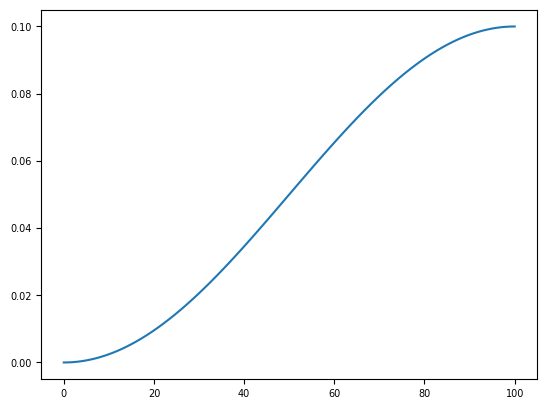

In [59]:
def setup_rho_schedule(n_total_steps, frequency=3.0):
    base_frequency = n_total_steps / (2*frequency)
    def rho_sched(x, base):
        return base * 0.5 * (1 - np.cos(x / base_frequency * np.pi))
    return rho_sched

rho_sched = setup_rho_schedule(100, frequency=0.5)

x = np.arange(0, 101)
y = rho_sched(x, 0.1)
import matplotlib.pyplot as plt
plt.plot(x, y)

In [62]:
from src.subspace_curve import LoraAbstractParams
rho_s = rho_sched(10, base=0.1)
rho_w = rho_sched(1, base=0.1)

s_model.set_lora_rho(rho_w, rho_s, params)
params['params']['layers_0']['self_attn']['v_proj']['kernel'].lora_rho_w, params['params']['layers_0']['self_attn']['v_proj']['kernel'].lora_rho_s
# params['params'] = jax.tree.map(lambda p: p.set_rho(rho_s=rho_s, rho_w=rho_w) if isinstance(p, LoraAbstractParams) else p, params['params'], is_leaf=lambda p: isinstance(p, LoraAbstractParams))
# s_model.curve_mask = jax.tree.map(lambda p: p.set_rho(rho_s=rho_s, rho_w=rho_w) if isinstance(p, LoraAbstractParams) else p, s_model.curve_mask, is_leaf=lambda p: isinstance(p, LoraAbstractParams))
# s_model.train_mask = jax.tree.map(lambda p: p.set_rho(rho_s=rho_s, rho_w=rho_w) if isinstance(p, LoraAbstractParams) else p, s_model.train_mask, is_leaf=lambda p: isinstance(p, LoraAbstractParams))

(2.467198171342e-05, 0.0024471741852423235)

## Load model and data from wandb

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = ".99"

from qwen_fineTuning_PtoC import load_text_classification_data, QwenTextClassificationWrapper
import wandb
from copy import deepcopy
from flax.core import freeze, unfreeze
from src.subspace_curve import filter_mask, LoRACategorySubspace, LoRAEntropyCategorySubspace
import jax
import numpy as np
import jax.numpy as jnp
from qwen_fineTuning_PtoC_fixCps import setup_metrics
from numpyro.distributions import Categorical
import pandas as pd
import seaborn as sns
import numpy as np

import matplotlib.pyplot as plt
from src.utils import calibration_error as ece_fn, post_pred_performance, init_model, load_checkpoint_new

%load_ext autoreload
%autoreload 2


api = wandb.Api()
run = api.run("ddold/qwen_PtoC/h97far1q")

config = deepcopy(run.config)

# config['dataset_path'] = "artifacts/winogrande_s_dataset:v0/test_data.npz"
config['dataset_path'] = "artifacts/obqa_dataset:v0/test_data.npz"
config['net_kwargs'] = {
    'model_path': "artifacts/qwen2.5_7B_bfloat16:v0/",
}

# run = wandb.init(project="qwen_PtoC", name="test_prediction")
test_input_ids, test_attention_mask, test_labels, test_target_ids, test_unique_target_ids = load_text_classification_data(config['dataset_path'], run=None)
key = jax.random.PRNGKey(config.get('rng_seed', 0))

test_input_ids.shape, test_attention_mask.shape, test_labels.shape, test_target_ids.shape, test_unique_target_ids.shape


((500, 127), (500, 127), (500,), (500,), (4, 1))

In [2]:
# load_DE_checkpoint (legacy) – kept here for reference only; use load_checkpoint_new from src.utils instead.
def load_DE_checkpoint(run, params):
    ''' Load trainable parameters from a wandb run artifact into the model parameters.
        Args:
            run: wandb run object containing the artifacts.
            params: current model parameters (flax format).
        Returns:
            params: updated model parameters with loaded trainable parameters.
    '''
    def load_art(load_run):
        artifact_use, artifact_weights_use = False, False
        print(f"Found config with obqa dataset with name: {load_run.name}, id: {load_run.id}")
        for art_l in load_run.logged_artifacts():
            if art_l.type == "pytree" and art_l.name.startswith("params"):
                print(f"Downloading params from {art_l.name}")
                artifact_use = art_l
            if art_l.type == "npz" and art_l.name.startswith("bma_weights"):
                print(f"Downloading weights from {art_l.name}")
                artifact_weights_use = art_l
        return artifact_use, artifact_weights_use

    artifact_use, artifact_weights_use = load_art(run)

    trainable_params = False
    for f in artifact_use.files():
        if 'trainable_params' in f.name:
            trainable_params = np.load(artifact_use.get_entry(f.name).download(), allow_pickle=True)
            print(f"Loaded trainable_params from {f.name}")
            assert len(set(trainable_params[0].keys()) - set(params['params'].keys())) == 0, "Loaded trainable_params do not match model params"
    assert trainable_params[0], f"trainable_params not found in artifact {artifact_use.name}"

    return trainable_params


##### check Rotation matrix

In [6]:
all_logs = {}
run = api.run("ddold/qwen_PtoC/oi5oy12b") # obqa seed=1 Asd(t)B  rho=0.5
# run = api.run("ddold/qwen_PtoC/rlqb5ark") # spark run
config = deepcopy(run.config)

config['dataset_path'] = "artifacts/winogrande_s_dataset:v0/test_data.npz"
# config['dataset_path'] = "artifacts/obqa_dataset:v0/test_data.npz"
config['net_kwargs'] = {
    'model_path': "artifacts/qwen2.5_7B_bfloat16:v0/",
}
config['curve_params']['k'] = len(config['curve_params']['cp_fix']) - 1
# config['lora_params']['lora_mode'] = "A(t)B"  # only fix first and last cp
# config['lora_params']['lora_rho_s'] = 0.0
# config['lora_params']['lora_rho'] = 0.0

train_input_ids, train_attention_mask, train_labels, train_target_ids, train_unique_target_ids = load_text_classification_data("artifacts/obqa_dataset:v0/train_data.npz", run=None, test=False)
test_input_ids, test_attention_mask, test_labels, test_target_ids, test_unique_target_ids = load_text_classification_data("artifacts/obqa_dataset:v0/test_data.npz", run=None, test=True)

s_model, params = init_model(config, train_unique_target_ids)
params, bma_weights, trainable_params, init_trainable_params, pretrained_params, _ = load_checkpoint_new(run, params, s_model)


# metric_fn = setup_metrics(s_model, 8, test_input_ids, test_attention_mask, test_labels, 20, use_linspace=True, average=False)

KeyboardInterrupt: 

In [ ]:
def set_rho(rho_s, rho_w, p):
    if isinstance(p, LoraAbstractParams):
        p.lora_rho_w = rho_w
        if hasattr(p, 'lora_rho_s'):
            p.lora_rho_s = rho_s
    return p
params['params'] = jax.tree.map(lambda p: set_rho(0.0, 0.0, p), params['params'], is_leaf=lambda p: isinstance(p, LoraAbstractParams))
s_model.curve_mask = jax.tree.map(lambda p: set_rho(0.0, 0.0, p), s_model.curve_mask, is_leaf=lambda p: isinstance(p, LoraAbstractParams))
s_model.train_mask = jax.tree.map(lambda p: set_rho(0.0, 0.0, p), s_model.train_mask, is_leaf=lambda p: isinstance(p, LoraAbstractParams))

In [8]:
from qwen_fineTuning_PtoC_fixCps import setup_metrics

metric_fn = setup_metrics(s_model, 8, test_input_ids, test_attention_mask, test_labels, 20, use_linspace=True, average=False)
metrics, logits = metric_fn(jax.random.PRNGKey(0), params)
post_pred_performance(logits, test_labels)

weights type <class 'bool'> for BMA prediction True


{'ll': Array(-0.6203182, dtype=float32),
 'acc': Array(0.78800005, dtype=float32),
 'ece': Array(0.10574083, dtype=float32)}

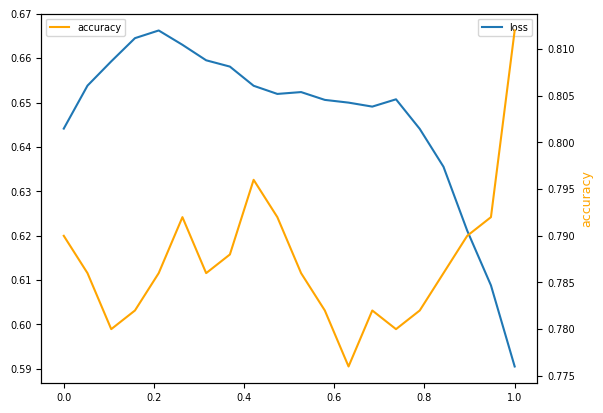

In [17]:
from matplotlib import pyplot as plt

plt.plot(np.linspace(0,1, len(metrics['loss'])), metrics['loss'], label='loss')
plt.gca().legend()
ax = plt.twinx()
ax.plot(np.linspace(0,1, len(metrics['loss'])), metrics['acc'], label='accuracy', c='orange')
ax.set_ylabel('accuracy', color='orange')
plt.gca().legend()

In [18]:
params['params']['layers_0']['self_attn']['q_proj']['kernel'].s

Array([-0.00525895,  0.0188717 ,  0.01014259,  0.01577702, -0.01933658,
        0.00899126,  0.00282675, -0.01764006], dtype=float32)

In [24]:
params['params']['layers_0']['self_attn']['q_proj']['kernel'].A.shape

(3, 8, 3584)

In [22]:
from src.subspace_curve import constrain_to_stiefel_mainfold

ar = constrain_to_stiefel_mainfold(params['params']['layers_0']['self_attn']['q_proj']['kernel'].A[0].T)

ar.shape

(896, 8)

In [18]:
ar

Array([[ 9.8112488e-01,  1.0525864e-02, -9.2813317e-03, ...,
        -1.1821598e-03,  1.4713627e-02, -7.2308062e-03],
       [ 1.0629775e-02,  9.9238366e-01,  3.2859230e-03, ...,
        -2.1521852e-04, -7.4378080e-03,  5.7428903e-03],
       [-7.2384765e-03,  2.0396244e-03,  9.7730553e-01, ...,
         5.2777021e-03,  7.1600988e-03,  5.9675416e-03],
       ...,
       [-3.4273928e-03,  1.3992377e-03,  6.7346310e-03, ...,
         1.3413187e-03,  8.3949119e-03, -2.3568198e-03],
       [-8.0840606e-03,  5.3090835e-03, -1.0089127e-02, ...,
         3.1643694e-03,  2.3588007e-03,  6.8907673e-04],
       [ 4.5992038e-03, -1.7811347e-03,  1.4404397e-02, ...,
        -2.5013420e-03,  1.9663328e-03, -1.6778810e-03]], dtype=float32)

In [23]:
ar2 = constrain_to_stiefel_mainfold(params['params']['layers_0']['self_attn']['q_proj']['kernel'].A[1].T)
ar3 = constrain_to_stiefel_mainfold(params['params']['layers_0']['self_attn']['q_proj']['kernel'].A[2].T)


In [50]:
jnp.diag(ar @ ar3.T)

Array([9.878286e-01, 9.917044e-01, 9.946359e-01, ..., 5.247182e-06,
       8.055567e-06, 8.626460e-06], dtype=float32)

In [51]:
jnp.abs(ar-ar3).mean()

Array(0.00170608, dtype=float32)

In [52]:
# comput Frobenius norm
f_norm = jnp.linalg.norm(ar-ar3, ord='fro')
f_norm


Array(0.3699632, dtype=float32)

In [55]:
jnp.sqrt(jnp.sum((ar-ar2)**2))

Array(0.40496153, dtype=float32)

In [59]:
jnp.trace(ar.T @ ar)

Array(7.9977436, dtype=float32)

In [60]:
jnp.arccos((jnp.trace(ar.T @ ar)-1)/2.)

Array(nan, dtype=float32)

In [64]:
# grassmanian distance
ar.T @ ar2
jnp.linalg.svd(ar.T @ ar2)

SVDResult(U=Array([[ 0.12575373,  0.01454796,  0.12572916,  0.797241  ,  0.2429862 ,
         0.08190703,  0.42343113,  0.29584992],
       [-0.060545  , -0.6317755 , -0.03680707, -0.25379407, -0.38088378,
         0.10034673,  0.40688014,  0.45905718],
       [ 0.22982669, -0.18006693,  0.7446779 , -0.14444461,  0.26480925,
        -0.04414126, -0.3909774 ,  0.33824724],
       [-0.03247403, -0.07662011,  0.2782881 , -0.26404387,  0.3319913 ,
        -0.4870466 ,  0.5954978 , -0.37928963],
       [-0.33471107,  0.68817085,  0.32796884, -0.19134706, -0.29413557,
         0.06672989,  0.26237276,  0.33227098],
       [-0.41511297, -0.16500646,  0.22572708, -0.05237203,  0.25948137,
         0.752498  ,  0.09213528, -0.32355267],
       [ 0.731362  ,  0.24270225, -0.15238017, -0.3437781 ,  0.1661219 ,
         0.40885365,  0.2607043 ,  0.04558653],
       [-0.32772774,  0.05140072, -0.41123483, -0.22775204,  0.6588629 ,
        -0.0786956 , -0.04875468,  0.4757073 ]], dtype=float32), S=A

In [75]:
arc = jnp.concat([ar, ar3], axis=1)
jnp.linalg.svd(arc).S

Array([1.4132118 , 1.4122651 , 1.4120171 , 1.4110404 , 1.4090627 ,
       1.4088361 , 1.4064063 , 1.3935186 , 0.24105383, 0.14839858,
       0.12320855, 0.12059221, 0.09468615, 0.07879943, 0.0742109 ,
       0.05323539], dtype=float32)

In [81]:
import jax.numpy as jnp

def grassmannian_distance_from_concat(s_values, k):
    """
    Computes distance using the singular values of concat([U1, U2]).
    Args:
        s_values: The full list of singular values from the concatenation.
        k: The number of columns (8 in your case).
    """
    # 1. Isolate the small values (the last k values)
    # These correspond to sqrt(1 - cos(theta))
    sigma_small = s_values[k:]  
    
    # 2. Convert to angles (radians) using half-angle formula
    # theta = 2 * arcsin(sigma / sqrt(2))
    thetas = 2 * jnp.arcsin(sigma_small / jnp.sqrt(2))
    
    # 3. Compute the L2 norm (Geodesic Distance)
    dist = jnp.linalg.norm(thetas)
    return dist, thetas

def grassmannian_distance_standard(U1, U2):
    """
    Standard way: SVD of the product U1.T @ U2
    """
    # 1. Compute cosine of principal angles
    # Singular values of the product represent cos(theta)
    S_cos = jnp.linalg.svd(jnp.dot(U1.T, U2), compute_uv=False)
    
    # 2. Clip to avoid NaNs (numerical precision can result in 1.0000001)
    S_cos = jnp.clip(S_cos, -1.0, 1.0)
    
    # 3. Get angles
    thetas = jnp.arccos(S_cos)
    
    # 4. Geodesic Distance
    dist = jnp.linalg.norm(thetas)
    return dist

# --- Your Example Usage ---
# Assuming ar1 and ar2 are (3580, 8)
s_vals = jnp.linalg.svd(jnp.concat([ar, ar2], axis=1)).S

# Method A (Using your current SVD output)
dist_a, angles = grassmannian_distance_from_concat(s_vals, k=8)

# Method B (Standard)
dist_b = grassmannian_distance_standard(ar, ar2)

print(f"Distance: {dist_a}")
print(f"Max angle (grad): {jnp.max(angles) * 180 / jnp.pi} degrees")
print(f"dist_b: {dist_b}")

Distance: 0.4760551154613495
Max angle (grad): 19.554014205932617 degrees
dist_b: 0.48131296038627625


In [ ]:
params['params']['layers_0']['self_attn']['q_proj']['kernel'].A.shape

(3, 8, 3584)

In [ ]:
pp = params['params']['layers_0']['self_attn']['q_proj']['kernel'].A[0]
jnp.abs(pp[:,8:]).mean()

##### rho scheduler last_model performance

In [7]:
all_logs = {}
run = api.run("ddold/qwen_PtoC/9whzu977") # obqa seed=1 A(t)B  rho=0.5 frequency=10
run = api.run("ddold/qwen_PtoC/sihru8bu") # obqa seed=1 Asd(t)eB  rho=0.25 and rho_s=1
# run = api.run("ddold/qwen_PtoC/rlqb5ark") # spark run
config = deepcopy(run.config)

ds = "winogrande_m"
config['dataset_path'] = f"artifacts/{ds}_dataset:v0/test_data.npz"
# config['dataset_path'] = "artifacts/obqa_dataset:v0/test_data.npz"
config['net_kwargs'] = {
    'model_path': "artifacts/qwen2.5_7B_bfloat16:v0/",
}
config['curve_params']['k'] = len(config['curve_params']['cp_fix']) - 1
# config['lora_params']['lora_mode'] = "A(t)B"  # only fix first and last cp
# config['lora_params']['lora_rho_s'] = 0.0
# config['lora_params']['lora_rho'] = 0.0

train_input_ids, train_attention_mask, train_labels, train_target_ids, train_unique_target_ids = load_text_classification_data(f"artifacts/{ds}_dataset:v0/train_data.npz", run=None, test=False)
test_input_ids, test_attention_mask, test_labels, test_target_ids, test_unique_target_ids = load_text_classification_data(f"artifacts/{ds}_dataset:v0/test_data.npz", run=None, test=True)

s_model, params = init_model(config, train_unique_target_ids)
params, bma_weights, trainable_params, init_trainable_params, pretrained_params, last_trainable_params = load_checkpoint_new(run, params, s_model)


# metric_fn = setup_metrics(s_model, 8, test_input_ids, test_attention_mask, test_labels, 20, use_linspace=True, average=False)

Using LoRA Mixin with rank=8, dtype=float32, alpha=16, mode=Asd(t)eB, rho=0.25, rho_s=1
Using Entropy Mixin 2 with weight: 0.0
Using Bezier curve parameterization
Found config with obqa dataset with name: test_half_val_rho_frequ=100, id: sihru8bu
Loaded last trainable_params from sihru8bu_last_trainable_params.npy
Loaded trainable_params from sihru8bu_trainable_params.npy


In [8]:
config

{'rng_seed': 1,
 'net_kwargs': {'model_path': 'artifacts/qwen2.5_7B_bfloat16:v0/'},
 'smoke_test': False,
 'lora_params': {'r': 8,
  'lora_rho': 0.25,
  'use_lora': True,
  'lora_mode': 'Asd(t)eB',
  'lora_alpha': 16,
  'lora_dtype': 'float32',
  'lora_rho_s': 1,
  'filter_masks': [{'op': 'all',
    'dims': [1, 0],
    'keys': ['self_attn', 'q_proj', 'kernel']},
   {'op': 'all', 'dims': [1, 0], 'keys': ['self_attn', 'v_proj', 'kernel']},
   {'op': 'all', 'dims': [1, 0], 'keys': ['lm_head', 'kernel']}],
  'rho_scheduler_frequency': 100},
 'save_params': True,
 'curve_params': {'cp_fix': [0, 0, 0],
  'gravity': 5,
  'num_steps': 5000,
  'batch_size': 4,
  'num_epochs': -1,
  'regularizer': False,
  'temperature': [1],
  'filter_masks': [{'op': 'all', 'keys': ['self_attn', 'q_proj', 'kernel']},
   {'op': 'all', 'keys': ['self_attn', 'v_proj', 'kernel']},
   {'op': 'all', 'keys': ['lm_head', 'kernel']}],
  'weight_decay': 0,
  'entropy_maxim': 0,
  'optimizer_conf': {'name': 'adamw',
   'k

In [9]:
params['params']['layers_0']['self_attn']['q_proj']['kernel']

LoRA(A=[[ 0.00329278 -0.00277938  0.01309018 ... -0.01091331  0.00127199
  -0.00871802]
 [-0.00039973  0.01101251 -0.01188195 ...  0.00641268 -0.00608283
   0.01052921]
 [-0.00180497 -0.0179047  -0.0057802  ...  0.00776695 -0.00464526
   0.01582853]
 ...
 [-0.00503175  0.0062161   0.02199737 ... -0.00881139 -0.00015997
  -0.01159324]
 [-0.01231755 -0.00012536 -0.00591244 ...  0.00384222 -0.01171356
  -0.01786275]
 [ 0.02710661  0.01366907 -0.02062537 ... -0.00865629 -0.00282137
   0.01082446]], s=[[ 0.79611826  1.1199416   1.2646158   2.5537667   1.2005492   0.4856507
   0.3232674   0.52708346]
 [-0.44037852  0.48241764  2.2866426   0.2677527   2.189673    0.9089487
  -1.5633873   0.07868613]
 [ 1.1753391   0.6418874   0.86140436  0.29422113  0.71417564 -1.1003884
   0.78367734  0.77125275]], B=[[ 3.4898911e-03  1.1495176e-03 -5.3535551e-03 ... -6.2774532e-05
   2.3877388e-03  6.6062650e-03]
 [-6.5219542e-04  3.5857808e-04 -2.6637269e-04 ...  6.7566585e-04
   4.9783452e-03 -3.0596864e-

In [10]:
from qwen_fineTuning_PtoC_fixCps import setup_metrics

metric_fn = setup_metrics(s_model, 8, test_input_ids, test_attention_mask, test_labels, 10, use_linspace=True, average=False)
metrics, logits = metric_fn(jax.random.PRNGKey(0), params)
post_pred_performance(logits, test_labels)

weights type <class 'bool'> for BMA prediction True


{'ll': Array(-0.48631236, dtype=float32),
 'acc': Array(0.7966667, dtype=float32),
 'ece': Array(0.07790802, dtype=float32)}

In [11]:
params = s_model.set_lora_rho(0., 0., params)

In [12]:
metric_fn = setup_metrics(s_model, 8, test_input_ids, test_attention_mask, test_labels, 10, use_linspace=True, average=False)
metrics, logits = metric_fn(jax.random.PRNGKey(0), params)
post_pred_performance(logits, test_labels)

weights type <class 'bool'> for BMA prediction True


{'ll': Array(-0.42945674, dtype=float32),
 'acc': Array(0.81416667, dtype=float32),
 'ece': Array(0.06205935, dtype=float32)}

In [13]:
def load_fn(m, p, pl):
    if m:
        assert p.shape == pl.shape, f"Shape mismatch for parameter with shape {p.shape} and loaded shape {pl.shape}"
        return pl
    else:
        return p
params['params'] = jax.tree.map(load_fn, s_model.train_mask, params['params'], last_trainable_params)

In [14]:
params['params']['layers_0']['self_attn']['q_proj']['kernel'].A

Array([[ 0.0048928 , -0.00482262,  0.01195862, ..., -0.01154788,
         0.00229806, -0.00821595],
       [-0.00017226,  0.0107748 , -0.0140026 , ...,  0.0063613 ,
        -0.00553478,  0.01026667],
       [-0.00261602, -0.01914797, -0.00452764, ...,  0.00814346,
        -0.00483419,  0.01532451],
       ...,
       [-0.00443864,  0.00652945,  0.02134126, ..., -0.00658051,
        -0.00018749, -0.01231923],
       [-0.01251666,  0.00096545, -0.00649254, ...,  0.00490643,
        -0.01278829, -0.01796022],
       [ 0.02786609,  0.01574476, -0.02222535, ..., -0.01226638,
         0.00058468,  0.01289325]], dtype=float32)

In [15]:
last_trainable_params['layers_0']['self_attn']['q_proj']['kernel'].A

Array([[ 0.0048928 , -0.00482262,  0.01195862, ..., -0.01154788,
         0.00229806, -0.00821595],
       [-0.00017226,  0.0107748 , -0.0140026 , ...,  0.0063613 ,
        -0.00553478,  0.01026667],
       [-0.00261602, -0.01914797, -0.00452764, ...,  0.00814346,
        -0.00483419,  0.01532451],
       ...,
       [-0.00443864,  0.00652945,  0.02134126, ..., -0.00658051,
        -0.00018749, -0.01231923],
       [-0.01251666,  0.00096545, -0.00649254, ...,  0.00490643,
        -0.01278829, -0.01796022],
       [ 0.02786609,  0.01574476, -0.02222535, ..., -0.01226638,
         0.00058468,  0.01289325]], dtype=float32)

In [16]:
# metric_fn = setup_metrics(s_model, 8, test_input_ids, test_attention_mask, test_labels, 10, use_linspace=True, average=False)
metrics, logits = metric_fn(jax.random.PRNGKey(0), params)
post_pred_performance(logits, test_labels)

weights type <class 'bool'> for BMA prediction True


{'ll': Array(-0.4641907, dtype=float32),
 'acc': Array(0.8258334, dtype=float32),
 'ece': Array(0.08793691, dtype=float32)}

In [17]:
params = s_model.set_lora_rho(rho_s=0., rho_w=0.5, params=params)

In [18]:
metrics, logits = metric_fn(jax.random.PRNGKey(0), params)
post_pred_performance(logits, test_labels)

weights type <class 'bool'> for BMA prediction True


{'ll': Array(-0.4661316, dtype=float32),
 'acc': Array(0.79, dtype=float32),
 'ece': Array(0.06976567, dtype=float32)}

In [19]:
metrics, logits = metric_fn(jax.random.PRNGKey(22), params)
post_pred_performance(logits, test_labels)

weights type <class 'bool'> for BMA prediction True


{'ll': Array(-0.45777234, dtype=float32),
 'acc': Array(0.79833335, dtype=float32),
 'ece': Array(0.05641827, dtype=float32)}

In [20]:
params['params'] = jax.tree.map(load_fn, s_model.train_mask, params['params'], trainable_params)

In [21]:
params = s_model.set_lora_rho(rho_s=0., rho_w=0.5, params=params)
metrics, logits = metric_fn(jax.random.PRNGKey(0), params)
post_pred_performance(logits, test_labels)

weights type <class 'bool'> for BMA prediction True


{'ll': Array(-0.4688054, dtype=float32),
 'acc': Array(0.77250004, dtype=float32),
 'ece': Array(0.04938882, dtype=float32)}

In [22]:
params = s_model.set_lora_rho(rho_s=0., rho_w=0.25, params=params)
metrics, logits = metric_fn(jax.random.PRNGKey(0), params)
post_pred_performance(logits, test_labels)

weights type <class 'bool'> for BMA prediction True


{'ll': Array(-0.4360327, dtype=float32),
 'acc': Array(0.805, dtype=float32),
 'ece': Array(0.06095393, dtype=float32)}

In [23]:
params = s_model.set_lora_rho(rho_s=0.5, rho_w=0., params=params)
metrics, logits = metric_fn(jax.random.PRNGKey(0), params)
post_pred_performance(logits, test_labels)

weights type <class 'bool'> for BMA prediction True


{'ll': Array(-0.4354183, dtype=float32),
 'acc': Array(0.815, dtype=float32),
 'ece': Array(0.0717729, dtype=float32)}

In [24]:
params = s_model.set_lora_rho(rho_s=1., rho_w=0., params=params)
metrics, logits = metric_fn(jax.random.PRNGKey(0), params)
post_pred_performance(logits, test_labels)

weights type <class 'bool'> for BMA prediction True


{'ll': Array(-0.45614743, dtype=float32),
 'acc': Array(0.80583334, dtype=float32),
 'ece': Array(0.0790548, dtype=float32)}

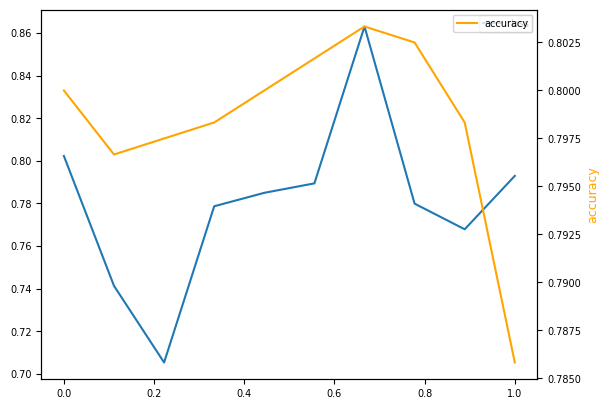

In [32]:
from matplotlib import pyplot as plt

plt.plot(np.linspace(0,1, len(metrics['loss'])), metrics['loss'], label='loss')
plt.gca().legend()
ax = plt.twinx()
ax.plot(np.linspace(0,1, len(metrics['loss'])), metrics['acc'], label='accuracy', c='orange')
ax.set_ylabel('accuracy', color='orange')
plt.gca().legend()

In [80]:
np.savez_compressed("boolq_dataset", **{f"train_{k}": v for k, v in np.load("artifacts/boolq_dataset:v0/train_data.npz").items()}, 
                    **{f"valid_{k}": v for k, v in np.load("artifacts/boolq_dataset:v0/test_data.npz").items()})

In [77]:
np.load("winogrande_m_dataset.npz")['train_labels'].shape

(2500,)

### Lora Mode Connect

#### single test

In [ ]:
all_logs = {}
# run = api.run("ddold/qwen_PtoC/d2xtr7rd") # obqa seed=1 Asd(t)eB  rho=0.25 and rho_s=1hjg23xum
run = api.run("ddold/qwen_PtoC/hjg23xum") # obqa seed=1 A(t)B(t)
# run = api.run("ddold/qwen_PtoC/rlqb5ark") # spark run
config = deepcopy(run.config)

ds = "winogrande_m"
config['dataset_path'] = f"artifacts/{ds}_dataset:v0/test_data.npz"
# config['dataset_path'] = "artifacts/obqa_dataset:v0/test_data.npz"
config['net_kwargs'] = {
    'model_path': "artifacts/qwen2.5_7B_bfloat16:v0/",
}
config['curve_params']['k'] = len(config['curve_params']['cp_fix']) - 1
# config['lora_params']['lora_mode'] = "A(t)B"  # only fix first and last cp
# config['lora_params']['lora_rho_s'] = 0.0
# config['lora_params']['lora_rho'] = 0.0

train_input_ids, train_attention_mask, train_labels, train_target_ids, train_unique_target_ids = load_text_classification_data(f"artifacts/{ds}_dataset:v0/train_data.npz", run=None, test=False)
test_input_ids, test_attention_mask, test_labels, test_target_ids, test_unique_target_ids = load_text_classification_data(f"artifacts/{ds}_dataset:v0/test_data.npz", run=None, test=True)

s_model, params = init_model(config, train_unique_target_ids)
params, bma_weights, trainable_params, init_trainable_params, pretrained_params, last_trainable_params = load_checkpoint_new(run, params, s_model)


# metric_fn = setup_metrics(s_model, 8, test_input_ids, test_attention_mask, test_labels, 20, use_linspace=True, average=False)

Using LoRA mode A(t)eB(t) with lora_rho_s=0 makes no sense and is equivalent to A(t)B(t).


Found config with obqa dataset with name: serene-sweep-9, id: d2xtr7rd
Loaded last trainable_params from d2xtr7rd_last_trainable_params.npy
Loaded init trainable_params from d2xtr7rd_pretrained_params.npy
Loaded trainable_params from d2xtr7rd_trainable_params.npy


In [7]:
config

{'rng_seed': 1,
 'net_kwargs': {'model_path': 'artifacts/qwen2.5_7B_bfloat16:v0/'},
 'lora_params': {'r': 8,
  'lora_rho': 0.5,
  'use_lora': True,
  'lora_mode': 'A(t)eB(t)',
  'lora_alpha': 16,
  'lora_dtype': 'float32',
  'lora_rho_s': 0,
  'filter_masks': [{'op': 'all',
    'dims': [1, 0],
    'keys': ['self_attn', 'q_proj', 'kernel']},
   {'op': 'all', 'dims': [1, 0], 'keys': ['self_attn', 'v_proj', 'kernel']},
   {'op': 'all', 'dims': [1, 0], 'keys': ['lm_head', 'kernel']}],
  'rho_scheduler_frequency': 50},
 'save_params': True,
 'curve_params': {'cp_fix': [1, 0, 1, 0, 1, 0, 1],
  'gravity': 0,
  'num_steps': 5000,
  'batch_size': 4,
  'num_epochs': -1,
  'regularizer': False,
  'temperature': [1],
  'filter_masks': [{'op': 'all', 'keys': ['self_attn', 'q_proj', 'kernel']},
   {'op': 'all', 'keys': ['self_attn', 'v_proj', 'kernel']},
   {'op': 'all', 'keys': ['lm_head', 'kernel']}],
  'weight_decay': 0,
  'entropy_maxim': 0,
  'optimizer_conf': {'name': 'adamw',
   'kwargs': {'w

In [8]:
params = s_model.set_lora_rho(rho_s=0., rho_w=0., params=params)
metric_fn = setup_metrics(s_model, 8, test_input_ids, test_attention_mask, test_labels, 60, use_linspace=True, average=False)
metrics, logits = metric_fn(jax.random.PRNGKey(0), params)
post_pred_performance(logits, test_labels)

{'ll': Array(-0.45465332, dtype=float32),
 'acc': Array(0.81583333, dtype=float32),
 'ece': Array(0.07778783, dtype=float32)}

In [10]:
metrics

{'loss': Array([0.4977968 , 0.45997393, 0.45239937, 0.4573407 , 0.46735466,
        0.47771603, 0.4877393 , 0.48948398, 0.49142897, 0.49273008,
        0.4946186 , 0.49298906, 0.48508197, 0.47605437, 0.47416437,
        0.4671474 , 0.4618647 , 0.46512938, 0.46698448, 0.4676622 ,
        0.47108284, 0.4751721 , 0.47092915, 0.473981  , 0.46285123,
        0.4626127 , 0.4650713 , 0.46951526, 0.47452605, 0.4759103 ,
        0.47579017, 0.47413307, 0.4707537 , 0.4589251 , 0.45275754,
        0.45000556, 0.45335066, 0.44696075, 0.44692335, 0.4430037 ,
        0.4391811 , 0.44112226, 0.44049585, 0.442165  , 0.4392979 ,
        0.43753356, 0.4442405 , 0.44832742, 0.46205524, 0.47468254,
        0.48146087, 0.4909747 , 0.4967754 , 0.4921042 , 0.48955727,
        0.47362924, 0.46687564, 0.45913604, 0.46311337, 0.4725658 ],      dtype=float32),
 'acc': Array(0.81583333, dtype=float32),
 'ece': Array(0.07778783, dtype=float32),
 'll': Array(-0.45465332, dtype=float32)}

ValueError: x and y must have same first dimension, but have shapes (60,) and (1,)

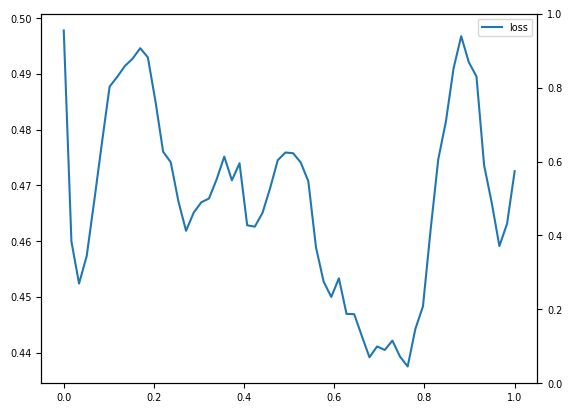

In [9]:
import matplotlib.pyplot as plt
plt.plot(np.linspace(0,1, len(metrics['loss'])), metrics['loss'], label='loss')
plt.gca().legend()
ax = plt.twinx()
ax.plot(np.linspace(0,1, len(metrics['loss'])), metrics['acc'], label='accuracy', c='orange')
ax.set_ylabel('accuracy', color='orange')
plt.gca().legend()  

In [11]:
params = s_model.set_lora_rho(rho_s=0., rho_w=0., params=params)
metric_fn = setup_metrics(s_model, 8, test_input_ids, test_attention_mask, test_labels, 15, use_linspace=True, average=False)
metrics, logits = metric_fn(jax.random.PRNGKey(0), params)
post_pred_performance(logits, test_labels)

{'ll': Array(-0.45735404, dtype=float32),
 'acc': Array(0.80916667, dtype=float32),
 'ece': Array(0.07811403, dtype=float32)}

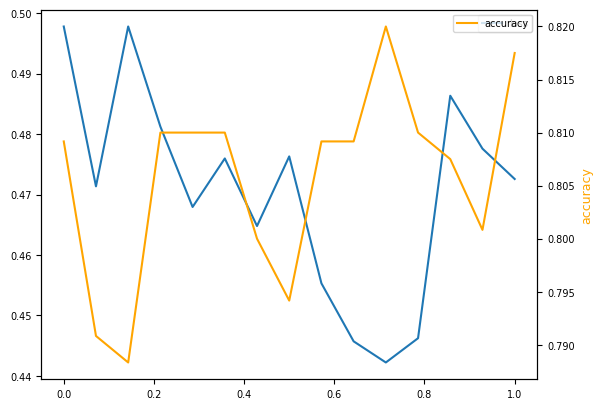

In [12]:
import matplotlib.pyplot as plt
plt.plot(np.linspace(0,1, len(metrics['loss'])), metrics['loss'], label='loss')
plt.gca().legend()
ax = plt.twinx()
ax.plot(np.linspace(0,1, len(metrics['loss'])), metrics['acc'], label='accuracy', c='orange')
ax.set_ylabel('accuracy', color='orange')
plt.gca().legend()  

#### test pretrained segments

In [3]:
all_logs = {}
run = api.run("ddold/qwen_PtoC/hjg23xum") # winogrande_m seed=1 A(t)B(t) with pretrained checkpoint for independent curve segments 
config = deepcopy(run.config)

ds = "winogrande_m"
config['dataset_path'] = f"artifacts/{ds}_dataset:v0/test_data.npz"
# config['dataset_path'] = "artifacts/obqa_dataset:v0/test_data.npz"
config['net_kwargs'] = {
    'model_path': "artifacts/qwen2.5_7B_bfloat16:v0/",
}
config['curve_params']['k'] = len(config['curve_params']['cp_fix']) - 1
# config['curve_params'].pop('gravity')
# config['lora_params']['lora_mode'] = "A(t)B"  # only fix first and last cp
# config['lora_params']['lora_rho_s'] = 0.0
# config['lora_params']['lora_rho'] = 0.0

train_input_ids, train_attention_mask, train_labels, train_target_ids, train_unique_target_ids = load_text_classification_data(f"artifacts/{ds}_dataset:v0/train_data.npz", run=None, test=False)
test_input_ids, test_attention_mask, test_labels, test_target_ids, test_unique_target_ids = load_text_classification_data(f"artifacts/{ds}_dataset:v0/test_data.npz", run=None, test=True)

s_model, params = init_model(config, train_unique_target_ids)
params, bma_weights, trainable_params, init_trainable_params, pretrained_params, last_trainable_params = load_checkpoint_new(run, params, s_model)


# metric_fn = setup_metrics(s_model, 8, test_input_ids, test_attention_mask, test_labels, 20, use_linspace=True, average=False)

Found run: young-sweep-7 (hjg23xum)
Loaded last_trainable_params from hjg23xum_last_trainable_params.npy
Loaded pretrained_params from hjg23xum_pretrained_params.npy
Loaded trainable_params from hjg23xum_trainable_params.npy


In [5]:
params = s_model.set_lora_rho(rho_s=0., rho_w=0., params=params)
metric_fn = setup_metrics(s_model, 8, test_input_ids, test_attention_mask, test_labels, n_samples=120, use_linspace=True, average=False)
metrics, logits = metric_fn(jax.random.PRNGKey(0), params)
post_pred_performance(logits, test_labels)

{'ll': Array(-0.44586685, dtype=float32),
 'acc': Array(0.8016667, dtype=float32),
 'ece': Array(0.06699058, dtype=float32)}

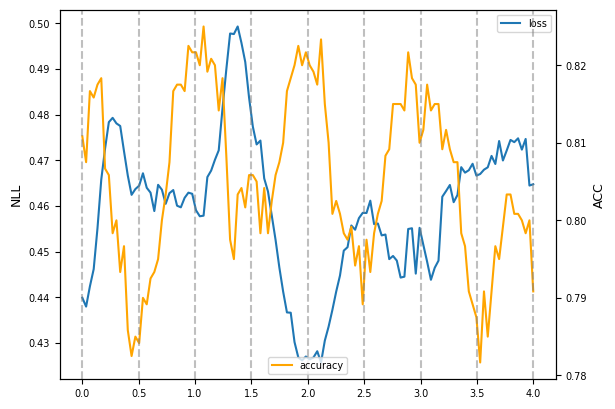

In [89]:
import matplotlib.pyplot as plt
t_space = np.linspace(0,s_model.t_max, len(metrics['loss']))
plt.plot(t_space, metrics['loss'], label='loss')
ax = plt.gca()
ax.legend()
ax.set_ylabel('NLL')

ax = plt.twinx()
ax.plot(t_space, metrics['acc'], label='accuracy', c='orange')
ax.set_ylabel('ACC')
ax.legend()  
# draw vertical lines for cp locations
for i, cp in enumerate(config['curve_params']['cp_fix']):
    plt.axvline(x=i/config['curve_params']['curve_segment'], color='grey', linestyle='--', alpha=0.5)

In [50]:
# curve performance
post_pred_performance(logits, test_labels)

{'ll': Array(-0.42199647, dtype=float32),
 'acc': Array(0.81583333, dtype=float32),
 'ece': Array(0.04115773, dtype=float32)}

In [11]:
jnp.savez("tmp_files/logits_and_metrics_winogrande_m.npz", logits=logits, labels=test_labels, **metrics)

In [98]:
log_sample_probs = jax.nn.log_softmax(logits, axis=-1)
log_sample_pmf = jnp.take_along_axis(log_sample_probs, test_labels[None, :, None], axis=-1).squeeze()
print(log_sample_pmf.shape)

# average over all samples
log_pmf = jax.scipy.special.logsumexp(log_sample_pmf, axis=0) - jnp.log(log_sample_pmf.shape[0])
mlppd = -jnp.mean(log_pmf)
print(f"MLPPD: {mlppd}")

pmd_at_DE = log_sample_pmf[::log_sample_pmf.shape[0]//(np.sum(config['curve_params']['cp_fix']) - 1)]
log_pmf_at_DE = jax.scipy.special.logsumexp(pmd_at_DE, axis=0) - jnp.log(pmd_at_DE.shape[0])
mlppd_at_DE = -jnp.mean(log_pmf_at_DE)
print(f"MLPPD at DE points: {mlppd_at_DE}")

(120, 1200)
MLPPD: 0.42199647426605225
MLPPD at DE points: 0.40469756722450256


In [ ]:
# only Fixed points performance (should be DE performance)
params = s_model.set_lora_rho(rho_s=0., rho_w=0., params=params)
metric_fn = setup_metrics(s_model, 8, test_input_ids, test_attention_mask, test_labels, n_samples=np.sum(config['curve_params']['cp_fix']), use_linspace=True, average=False)
metrics_fix, logits_fix = metric_fn(jax.random.PRNGKey(0), params)
post_pred_performance(logits_fix, test_labels)


{'ll': Array(-0.40699846, dtype=float32),
 'acc': Array(0.81916666, dtype=float32),
 'ece': Array(0.0415621, dtype=float32)}

In [ ]:
metrics_fix

{'loss': Array([0.43993568, 0.46190712, 0.4297125 , 0.45646137, 0.46477607],      dtype=float32),
 'acc': Array([0.8108333, 0.8208333, 0.8191666, 0.8133333, 0.7908333], dtype=float32),
 'ece': Array([0.06922037, 0.08399712, 0.0578546 , 0.0770136 , 0.08455008],      dtype=float32),
 'bma_ll': Array(-0.40699846, dtype=float32),
 'bma_acc': Array(0.81916666, dtype=float32),
 'bma_ece': Array(0.0415621, dtype=float32)}

In [115]:
# nll for each fix and inbetween point
pmd_at_DE = log_sample_pmf[::15]
pmd_at_DE = jnp.concat([pmd_at_DE, log_sample_pmf[-1:]], axis=0)
log_pmf_at_DE = jax.scipy.special.logsumexp(pmd_at_DE, axis=0) - jnp.log(pmd_at_DE.shape[0])
mlppd_at_DE = -jnp.mean(log_pmf_at_DE)
print(f"MLPPD at DE points: {mlppd_at_DE}")
pmd_at_DE.mean(axis=1)


MLPPD at DE points: 0.4114859104156494


Array([-0.4399357 , -0.46446759, -0.45908678, -0.47739705, -0.42643806,
       -0.45848534, -0.45149675, -0.46702027, -0.46477613], dtype=float32)

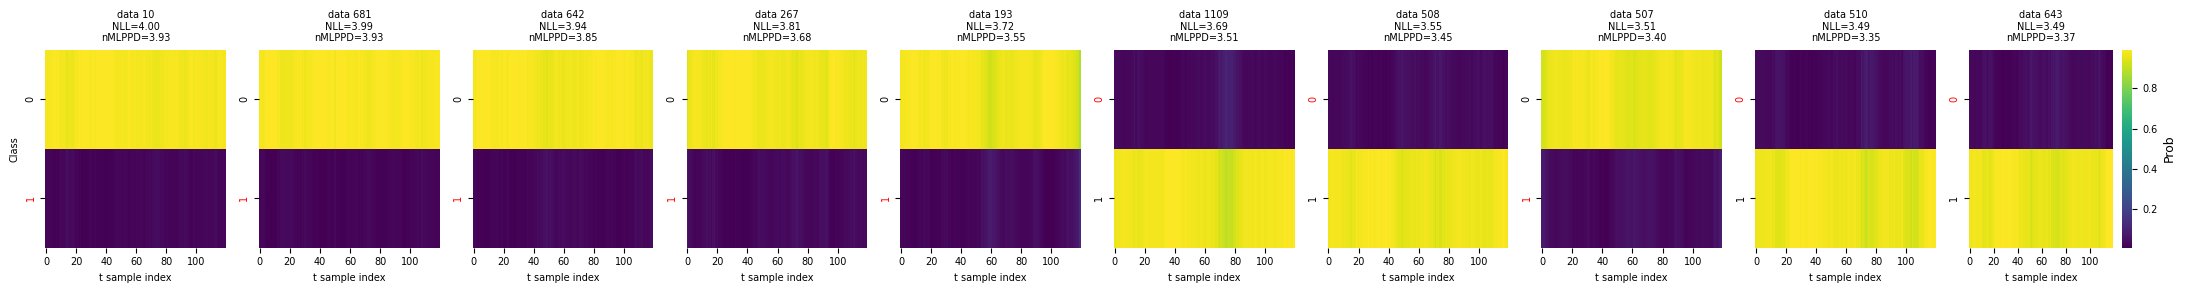

In [130]:

# plot class probs along curve for the top-k most uncertain data points
# logits: (n_t, n_data, n_cls)  |  test_labels: (n_data,)
top_k = 10

nll = -Categorical(logits=logits).log_prob(test_labels[None, :])   # (n_t, n_data)
top_data_idx = nll.mean(0).argsort()[-top_k:][::-1]               # highest NLL first

n_t, n_data, n_cls = logits.shape

fig, axes = plt.subplots(1, top_k, figsize=(2.2 * top_k, 3.0), squeeze=False)

for col_j, data_idx in enumerate(top_data_idx):
    ax = axes[0, col_j]

    # class probs along t  →  (n_cls, n_t)
    probs_along_t = np.array(jax.nn.softmax(logits[:, data_idx, :], axis=-1).T)

    sns.heatmap(probs_along_t, cmap='viridis', ax=ax,
                cbar=(col_j == top_k - 1),
                cbar_kws={'label': 'Prob'} if col_j == top_k - 1 else {},
                xticklabels=max(1, n_t // 6),
                yticklabels=True)

    correct_cls = int(test_labels[data_idx])
    ax.set_yticks(np.arange(n_cls) + 0.5)
    ax.set_yticklabels([str(c) for c in range(n_cls)], fontsize=7)
    for tl in ax.get_yticklabels():
        tl.set_color('red' if int(tl.get_text()) == correct_cls else 'black')

    mean_nll = float(nll.mean(0)[data_idx])
    mlppd = -np.log(probs_along_t.T[:, int(test_labels[data_idx])].mean() + 1e-16)  # add small epsilon to avoid log(0)
    ax.set_title(f'data {int(data_idx)}\nNLL={mean_nll:.2f}\nnMLPPD={mlppd:.2f}', fontsize=7)
    ax.set_xlabel('t sample index', fontsize=7)
    if col_j == 0:
        ax.set_ylabel('Class', fontsize=7)
    else:
        ax.set_ylabel('')

fig.tight_layout()
plt.show()


(2, 5)
(2, 5)
(2, 5)
(2, 5)
(2, 5)
(2, 5)
(2, 5)
(2, 5)
(2, 5)
(2, 5)


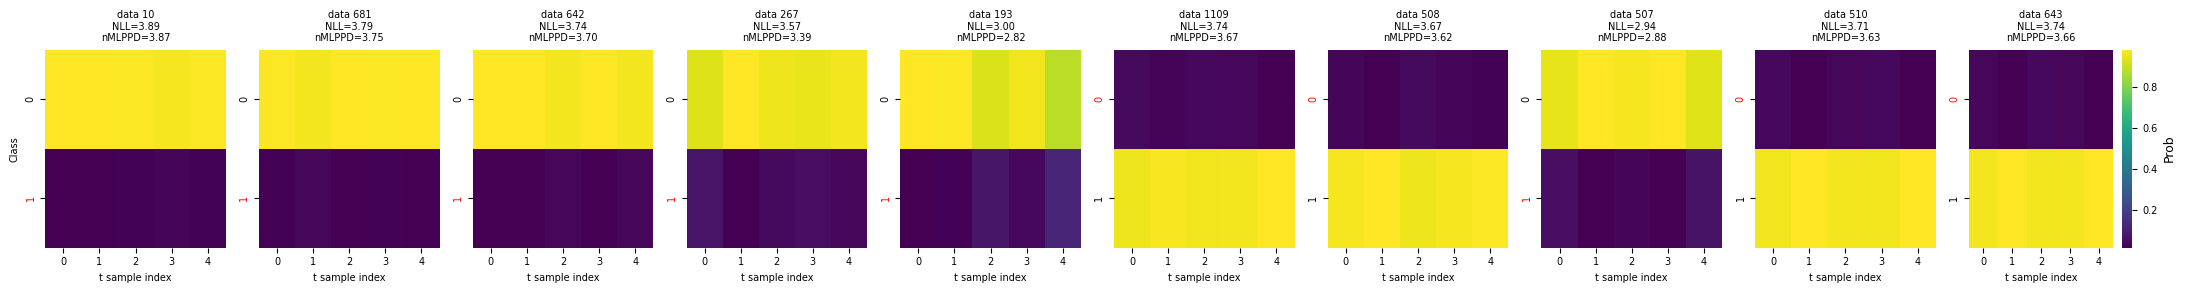

In [ ]:
# plot class probs along curve for the top-k most uncertain data points
# logits: (n_t, n_data, n_cls)  |  test_labels: (n_data,)
top_k = 10
subset_logit = logits[::30]  # subsample for smoother visualization
subset_logit = jnp.concatenate([subset_logit, logits[-1:]], axis=0)  # ensure last point is included   
nll = -Categorical(logits=subset_logit).log_prob(test_labels[None, :])   # (n_t, n_data)
# top_data_idx = nll.mean(0).argsort()[-top_k:][::-1]               # highest NLL first

n_t, n_data, n_cls = subset_logit.shape

fig, axes = plt.subplots(1, top_k, figsize=(2.2 * top_k, 3.0), squeeze=False)

for col_j, data_idx in enumerate(top_data_idx):
    ax = axes[0, col_j]

    # class probs along t  →  (n_cls, n_t)
    probs_along_t = np.array(jax.nn.softmax(subset_logit[:, data_idx, :], axis=-1).T)

    sns.heatmap(probs_along_t, cmap='viridis', ax=ax,
                cbar=(col_j == top_k - 1),
                cbar_kws={'label': 'Prob'} if col_j == top_k - 1 else {},
                xticklabels=max(1, n_t // 6),
                yticklabels=True)

    correct_cls = int(test_labels[data_idx])
    ax.set_yticks(np.arange(n_cls) + 0.5)
    ax.set_yticklabels([str(c) for c in range(n_cls)], fontsize=7)
    for tl in ax.get_yticklabels():
        tl.set_color('red' if int(tl.get_text()) == correct_cls else 'black')

    mean_nll = float(nll.mean(0)[data_idx])
    mlppd = -np.log(probs_along_t.T[:, int(test_labels[data_idx])].mean() + 1e-8)  # add small epsilon to avoid log(0)
    ax.set_title(f'data {int(data_idx)}\nNLL={mean_nll:.2f}\nnMLPPD={mlppd:.2f}', fontsize=7)
    ax.set_xlabel('t sample index', fontsize=7)
    if col_j == 0:
        ax.set_ylabel('Class', fontsize=7)
    else:
        ax.set_ylabel('')

fig.tight_layout()
plt.show()


#### go trough all runs in sweep

In [11]:
from src.subspace_curve import LoRACategorySubspace, filter_mask
import inspect
sig = inspect.signature(LoRACategorySubspace.__init__)
print(sig)
all_sig = {}
for cs in LoRACategorySubspace.__mro__:
    if cs == object:
        continue
    sig = inspect.signature(cs.__init__)
    all_sig = {**sig.parameters, **all_sig}
all_sig.pop('self', None)
all_sig.pop('kwargs', None)
all_sig

(self, r, lora_mask, lora_dtype: str, lora_alpha: float, lora_mode: str = 'A(t)B', lora_rho: float = 0.0, lora_rho_s: float = 0.0, **kwargs)


{'model': <Parameter "model">,
 'k': <Parameter "k">,
 'weight_decay': <Parameter "weight_decay: float = 0.0">,
 'perm_spec': <Parameter "perm_spec: src.weight_matching.PermutationSpec = False">,
 'natural_parameterization': <Parameter "natural_parameterization=False">,
 'mutuable_param_name': <Parameter "mutuable_param_name: str | bool = False">,
 'curve_parameterization': <Parameter "curve_parameterization='bezier'">,
 'curve_segment': <Parameter "curve_segment: int | bool = False">,
 'indepent_connected': <Parameter "indepent_connected: bool = False">,
 'r': <Parameter "r">,
 'lora_mask': <Parameter "lora_mask">,
 'lora_dtype': <Parameter "lora_dtype: str">,
 'lora_alpha': <Parameter "lora_alpha: float">,
 'lora_mode': <Parameter "lora_mode: str = 'A(t)B'">,
 'lora_rho': <Parameter "lora_rho: float = 0.0">,
 'lora_rho_s': <Parameter "lora_rho_s: float = 0.0">}

In [ ]:
from tqdm import tqdm

# Sweep id passed as a variable – change as needed
SWEEP_ID = "3p3okc1w"
ds = "winogrande_m"

t_bar = tqdm(api.sweep(f"ddold/qwen_PtoC/{SWEEP_ID}").runs)
t_bar.set_description(f"Sweep id: {SWEEP_ID}")
for run in t_bar:
    config = deepcopy(run.config)

    config['dataset_path'] = f"artifacts/{ds}_dataset:v0/test_data.npz"
    config['net_kwargs'] = {
        'model_path': "artifacts/qwen2.5_7B_bfloat16:v0/",
    }

    # Load data inside the loop
    test_input_ids, test_attention_mask, test_labels, test_target_ids, test_unique_target_ids = \
        load_text_classification_data(config['dataset_path'], run=None, test=True)

    config['curve_params']['k'] = 0
    s_model, params = init_model(config, test_unique_target_ids)
    params, bma_weights, trainable_params, init_trainable_params, pretrained_params, last_trainable_params = load_checkpoint_new(run, params, s_model)

    metric_fn = setup_metrics(s_model, 8, test_input_ids, test_attention_mask, test_labels, 1, use_linspace=True, average=False)
    all_logits = []
    all_metrics = []
    for p_param in pretrained_params:
        if p_param:
            params['params'] = jax.tree.map(load_fn, s_model.train_mask, params['params'], p_param)
            params = s_model.set_lora_rho(rho_s=0., rho_w=0., params=params)
            metrics, logits = metric_fn(jax.random.PRNGKey(0), params)
            all_logits.append(logits)
            all_metrics.append(metrics)

    logits_test = jnp.stack(all_logits, axis=0).squeeze()  # shape (n_ensembles, n_data, output_dim)
    print(f"Shape stacked logits {logits_test.shape}")

    # compute accuracy
    log_probs = jax.nn.log_softmax(logits_test, axis=-1)
    post_predict_logits = jax.nn.logsumexp(log_probs, axis=0) - jnp.log(log_probs.shape[0])

    preds = jnp.argmax(post_predict_logits, axis=-1)
    accuracy = jnp.mean(preds == test_labels)
    # compute ece
    ece = ece_fn(post_predict_logits, test_labels, num_bins=15)
    # compute nll for averaged probs
    ll = dist.Categorical(logits=post_predict_logits).log_prob(test_labels).mean()

    print("\033[94m" + f"Post-prediction performance: Accuracy={accuracy:.4f}, ECE={ece:.4f}, NLL={-ll:.4f}" + "\033[0m")
    run.summary['de_post_pred_acc'] = accuracy
    run.summary['de_post_pred_ece'] = ece
    run.summary['de_post_pred_ll'] = ll
    run.summary.update()

    del params


Sweep id: 3p3okc1w:   0%|          | 0/16 [00:00<?, ?it/s]

Using LoRA Mixin with rank=64, dtype=float32, alpha=16, mode=A(t)eB(t), rho=0.5, rho_s=0.1
Using Entropy Mixin 2 with weight: 0.0
Using B-Spline curve parameterization
Found config with obqa dataset with name: daily-sweep-16, id: p4t12n0z
Loaded last trainable_params from p4t12n0z_last_trainable_params.npy
Loaded init trainable_params from p4t12n0z_pretrained_params.npy
Loaded trainable_params from p4t12n0z_trainable_params.npy
Error loading trainable parameters: Shape mismatch for parameter with shape (64, 3584) and loaded shape (7, 64, 3584)
Shape stacked logits (4, 1200, 2)


Sweep id: 3p3okc1w:   6%|▋         | 1/16 [08:50<2:12:30, 530.02s/it]

Post-prediction performance: Accuracy=0.8242, ECE=0.0543, NLL=0.4198
Using LoRA Mixin with rank=64, dtype=float32, alpha=16, mode=A(t)eB(t), rho=0.5, rho_s=0.1
Using Entropy Mixin 2 with weight: 0.0
Using B-Spline curve parameterization
Found config with obqa dataset with name: chocolate-sweep-15, id: tqu11ijt
Loaded last trainable_params from tqu11ijt_last_trainable_params.npy
Loaded init trainable_params from tqu11ijt_pretrained_params.npy
Loaded trainable_params from tqu11ijt_trainable_params.npy
Error loading trainable parameters: Shape mismatch for parameter with shape (64, 3584) and loaded shape (7, 64, 3584)


Sweep id: 3p3okc1w:  12%|█▎        | 2/16 [17:45<2:04:25, 533.29s/it]

Shape stacked logits (4, 1200, 2)
Post-prediction performance: Accuracy=0.8108, ECE=0.0821, NLL=0.4340
Using LoRA Mixin with rank=8, dtype=float32, alpha=16, mode=A(t)eB(t), rho=0.5, rho_s=0.1
Using Entropy Mixin 2 with weight: 0.0
Using B-Spline curve parameterization
Found config with obqa dataset with name: dazzling-sweep-14, id: uz26th39
Loaded last trainable_params from uz26th39_last_trainable_params.npy
Loaded init trainable_params from uz26th39_pretrained_params.npy
Loaded trainable_params from uz26th39_trainable_params.npy
Error loading trainable parameters: Shape mismatch for parameter with shape (8, 3584) and loaded shape (7, 8, 3584)
Shape stacked logits (4, 1200, 2)
Post-prediction performance: Accuracy=0.8150, ECE=0.0519, NLL=0.4161


... (23 outputs left out)

Using LoRA Mixin with rank=8, dtype=float32, alpha=16, mode=A(t)eB(t), rho=0.5, rho_s=0
Using Entropy Mixin 2 with weight: 0.0
Using B-Spline curve parameterization
Using LoRA mode A(t)eB(t) with lora_rho_s=0 makes no sense and is equivalent to A(t)B(t).
Found config with obqa dataset with name: proud-sweep-2, id: rk9canv7
Loaded last trainable_params from rk9canv7_last_trainable_params.npy
Loaded init trainable_params from rk9canv7_pretrained_params.npy
Loaded trainable_params from rk9canv7_trainable_params.npy
Error loading trainable parameters: Shape mismatch for parameter with shape (8, 3584) and loaded shape (5, 8, 3584)
Shape stacked logits (3, 1200, 2)
Post-prediction performance: Accuracy=0.8192, ECE=0.0571, NLL=0.4243


Sweep id: 3p3okc1w:  94%|█████████▍| 15/16 [1:43:32<05:59, 359.04s/it]

Using LoRA Mixin with rank=8, dtype=float32, alpha=16, mode=A(t)eB(t), rho=0.5, rho_s=0
Using Entropy Mixin 2 with weight: 0.0
Using B-Spline curve parameterization
Using LoRA mode A(t)eB(t) with lora_rho_s=0 makes no sense and is equivalent to A(t)B(t).
Found config with obqa dataset with name: worldly-sweep-1, id: xa1izah1
Loaded last trainable_params from xa1izah1_last_trainable_params.npy
Loaded init trainable_params from xa1izah1_pretrained_params.npy
Loaded trainable_params from xa1izah1_trainable_params.npy
Error loading trainable parameters: Shape mismatch for parameter with shape (8, 3584) and loaded shape (5, 8, 3584)
Shape stacked logits (3, 1200, 2)
Post-prediction performance: Accuracy=0.8225, ECE=0.0529, NLL=0.4293


Sweep id: 3p3okc1w: 100%|██████████| 16/16 [1:48:29<00:00, 406.82s/it]


In [ ]:
# evaluation (Compare ModeConnect vs DE) in analyse.ipynb 

In [7]:
class Env:
    optimizer = "initial"

env = Env()

def make_step(env):
    optimizer = env.optimizer  # captured by value here
    def step():
        return optimizer       # uses local var, not env.optimizer
    return step

step = make_step(env)
env.optimizer = "new"

print(step())        # → "initial"  (not "new")
print(env.optimizer) # → "new"

initial
new


In [2]:
import numpy as np
batches_per_epoch = 10 // max(2, 1)
epochs = np.repeat(np.arange(2), batches_per_epoch)
epochs

array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1])

In [11]:
import optax

optax.sgd

<function optax._src.alias.sgd(learning_rate: Union[float, jax.Array, collections.abc.Callable[[Union[jax.Array, numpy.ndarray, numpy.bool_, numpy.number, float, int]], Union[jax.Array, numpy.ndarray, numpy.bool_, numpy.number, float, int]]], momentum: Optional[float] = None, nesterov: bool = False, accumulator_dtype: Optional[Any] = None) -> optax._src.base.GradientTransformationExtraArgs>

In [9]:
cps_fixed = [bool(v) for v in [1,0,0]]
cps_fixed

[True, False, False]

In [9]:
from dataclasses import dataclass, field
from contextlib import contextmanager

@dataclass
class test():
    name: str = "default"
    value: int = 0
    list_val: list = field(default_factory=list)

@contextmanager
def single_point_mask(d:test):
    """Temporarily set k=0 on *s_model* by zeroing its curve mask.

    Saves the original ``k`` and ``curve_mask`` on entry and restores both on
    exit.  The body of the ``with`` block sees the model as a single-point
    (k=0) model — useful for pretraining individual fixed control points
    without altering the outer curve model.
    """
    original_k = d.value
    original_list = d.list_val
    d.value = 10
    d.list_val = [2,]
    try:
        yield d 
    finally:
        d.value = original_k
        d.list_val = original_list

tt = test(list_val=[1,2,3])
print(tt)
with single_point_mask(tt) as masked_tt:
    print("Inside context:", masked_tt)
print("Outside context:", tt)

test(name='default', value=0, list_val=[1, 2, 3])
Inside context: test(name='default', value=10, list_val=[2])
Outside context: test(name='default', value=0, list_val=[1, 2, 3])


In [3]:
from src.subspace_curve import CategorySubspace, filter_mask, LoRACategorySubspace
import jax
import jax.numpy as jnp
from qwen_fineTuning_PtoC import QwenTextClassificationWrapper

# with lora
def setup_lora_subspace(key, k):
    model = QwenTextClassificationWrapper("artifacts/qwen2.5_0.5B_bfloat16:v0/", target_token_ids=all_target_ids)

    params = model.init(None, None)
    params = unfreeze(params)

    lora_mask = jax.tree.map(lambda x: False, params)['params']
    lora_mask = filter_mask(lora_mask, "self_attn", "q_proj", "kernel", as_curve=np.array([1,0]))
    lora_mask = filter_mask(lora_mask, "self_attn", "v_proj", "kernel", as_curve=np.array([1,0]))

    # key = jax.random.PRNGKey(0)
    s_model = LoRACategorySubspace(model=model, k=k, lora_mask=lora_mask, r=8, lora_dtype='float32', lora_alpha=16., lora_mode='A(t)B', lora_rho=1.0, lora_rho_s=2., weight_decay=0.01, perm_spec=False, mutuable_param_name=False, curve_parameterization='bezier')

    curve_mask = jax.tree.map(lambda x: False, params)['params']
    if k > 0:
        curve_mask = filter_mask(curve_mask, "self_attn", "q_proj", "kernel", as_curve=True)
        curve_mask = filter_mask(curve_mask, "self_attn", "v_proj", "kernel", as_curve=True)

    train_mask = jax.tree.map(lambda x: False, params['params'])
    train_mask = filter_mask(train_mask, "self_attn", "q_proj", "kernel", as_curve=True)
    train_mask = filter_mask(train_mask, "self_attn", "v_proj", "kernel", as_curve=True)

    s_params = s_model.init_params_from_point(key, params, curve_mask, noise_fn=lambda p, key: p)
    del params

    train_mask = s_model.update_mask_for_lora(train_mask, s_params['params'], b_off=False, w0_off=True) # w0 must be off for LoRA
    s_model.set_train_mask(train_mask)
    return s_model, s_params

s_model, params = setup_lora_subspace(jax.random.PRNGKey(22), k=2)
params['params']['layers_0']['self_attn']['q_proj']['kernel'].shape

{'A': (3, 8, 896), 'B': (896, 8), 'w0': (896, 896)}

In [7]:
from src.subspace_curve import CategorySubspace, filter_mask, LoRACategorySubspace
import jax
import jax.numpy as jnp
from qwen_fineTuning_PtoC import QwenTextClassificationWrapper
from copy import deepcopy

# with lora
def setup_lora_subspace(k):
    model = QwenTextClassificationWrapper("artifacts/qwen2.5_0.5B_bfloat16:v0/", target_token_ids=all_target_ids)
    s_model = LoRACategorySubspace(model=model, k=k, r=8, lora_dtype='float32', lora_alpha=16., lora_mode='A(t)B', lora_rho=1.0, lora_rho_s=2., weight_decay=0.01, perm_spec=False, mutuable_param_name=False, curve_parameterization='bezier')
    return s_model

def init_params(key, s_model):

    params = s_model.model.init(None, None)
    params = unfreeze(params)

    lora_mask = jax.tree.map(lambda x: False, params['params'])
    lora_mask = filter_mask(lora_mask, "self_attn", "q_proj", "kernel", as_curve=np.array([1,0]))
    lora_mask = filter_mask(lora_mask, "self_attn", "v_proj", "kernel", as_curve=np.array([1,0]))
    curve_mask = jax.tree.map(lambda x: False, params['params'])
    if s_model.k > 0:
        curve_mask = filter_mask(curve_mask, "self_attn", "q_proj", "kernel", as_curve=True)
        curve_mask = filter_mask(curve_mask, "self_attn", "v_proj", "kernel", as_curve=True)

    train_mask = jax.tree.map(lambda x: False, params['params'])
    train_mask = filter_mask(train_mask, "self_attn", "q_proj", "kernel", as_curve=True)
    train_mask = filter_mask(train_mask, "self_attn", "v_proj", "kernel", as_curve=True)

    params = s_model.init_params_from_point(key, params, curve_mask, noise_fn=lambda p, key: p, lora_mask=lora_mask)

    train_mask = s_model.update_mask_for_lora(train_mask, params['params'], b_off=False, w0_off=True) # w0 must be off for LoRA
    s_model.set_train_mask(train_mask)
    return params

s_model = setup_lora_subspace(k=2)
params = init_params(jax.random.PRNGKey(22), s_model)

params['params']['layers_0']['self_attn']['q_proj']['kernel'].shape

{'A': (3, 8, 896), 'B': (896, 8), 'w0': (896, 896)}

### end
